In [2]:
import sklearn
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

**Please write your name below** (in case the file names get mixed up)

Adel Sahuc

# Dataset

Let's load data for classification. This data is generated and does not a precise meaning: the idea will be to build intuition about what is going on with different models.

Dataset can be downloaded here: https://drive.google.com/file/d/1Sy0Ly4Xj8fzPAiPru9oFS6evgQjuNMs4/view?usp=sharing

In [3]:
# Load the dataset;
# make sure that the file is located in the same folder as the notebook
# (or change the path)
dataset = np.load("datasetLab6.npy")

In [4]:
# Extract features and targets
X = dataset[:,:2] # features are first 2 columns
y = dataset[:,-1] # labels are last column
print(f'Shape of feature matrix: {X.shape}')

Shape of feature matrix: (300, 2)


## Bagging and boosting

**Fit a bagging model on the dataset, and measure your performance.**

Make sure your methodology is correct.

**Display the resulting probability heatmap**

Test accuracy: 0.96


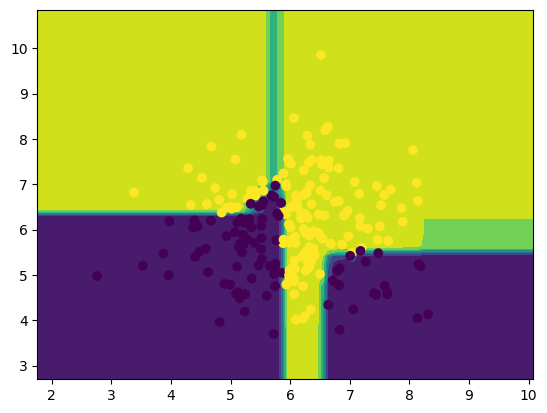

In [5]:
"""
Hope I did this correct but I am trying ot follow the 1-NN/5-NN figure in lecture 7 slide 27.
"""
from sklearn.model_selection import train_test_split 
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import DecisionBoundaryDisplay

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

bag_classifier = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
  n_estimators=100,
      random_state=0,
)

bag_classifier.fit(X_train, y_train)

print("Test accuracy:", bag_classifier.score(X_test, y_test))
# accuracy 0.96
# ok lets make heatmap

disp = DecisionBoundaryDisplay.from_estimator(bag_classifier, X, response_method="predict_proba")
disp.ax_.scatter(X_train[:, 0], X_train[:, 1], c=y_train)
plt.show()

**Fit a boosting model on the dataset, measure the performance and display the heatmap.**

Best params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
CV accuracy (train  set only): 0.95995670995671
Test accuracy: 0.9333333333333333


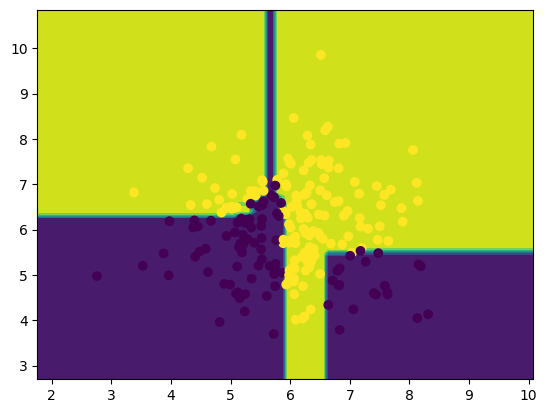

In [6]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

param_grid = {
    "n_estimators": [10, 50, 100, 200],
   "learning_rate": [0.1, 0.05, 0.005, 0.0005],
      "max_depth": [1, 2, 3, 6]
}

grid = GridSearchCV(GradientBoostingClassifier(random_state=0), param_grid, cv=7, scoring="accuracy", n_jobs=-1)

grid.fit(X_train, y_train)

boost_classifier = grid.best_estimator_
print("Best params:", grid.best_params_)
print(f"CV accuracy (train  set only): {grid.best_score_}")
# oooh interesting so the one before got close too our very simple grid search

print(f"Test accuracy: {accuracy_score(y_test, boost_classifier.predict(X_test))}")

# ok lets make a heatmap here 

disp = DecisionBoundaryDisplay.from_estimator(boost_classifier, X,
    response_method="predict_proba",
)

disp.ax_.scatter(X_train[:, 0], X_train[:, 1], c=y_train)
plt.show()

**Is your model over-confident? Under-confident?**

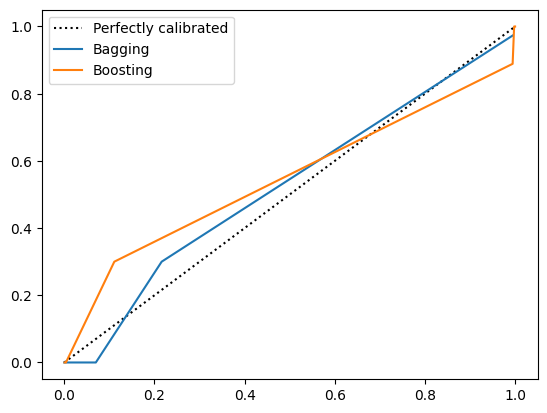

In [7]:
from sklearn.calibration import calibration_curve

models = {"Bagging": bag_classifier, "Boosting": boost_classifier}

fig, ax = plt.subplots()
ax.plot([0, 1], [0, 1], "k:", label="Perfectly calibrated")


for name, model in models.items():
    proba = model.predict_proba(X_test)[:, 1]
    frac_pos, mean_prediction = calibration_curve(y_test, proba, n_bins=8, strategy="quantile")
    ax.plot(mean_prediction, frac_pos, label=name)


ax.legend()
plt.show()


So the calibration curves that boost is over confident for low prediction probabilities and that the true fraction of the positives is higher than the prediction. Also, the fraction of positives is lower than predicted for very high probabilities (it has a s shaped curve like the lecture in class). 
Bagging stays much closer to the diagonal line (meaning it's well calibrated). This makes intuitive sense as bagging averages many models (in our case trees) which smooths the probability while boosting aims to have the smallest training error directly by having other models correct for the previous models errors.


## Multi-class, higher dimension classification

For this part, we are going to use the MNIST dataset again. We can download a lower-dimension version of the one we used in lab 3, with images of size 8x8, using scikit-learn utility functions. Initially, values are between 0 and 16. We will normalize them to values between 0 and 1.

In [8]:
from sklearn.datasets import load_digits

In [9]:
digits = load_digits(return_X_y=False)

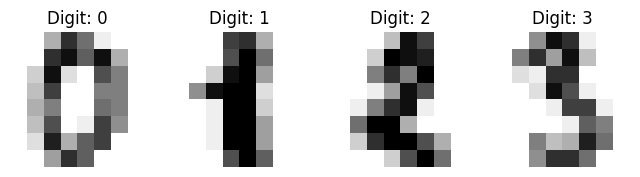

In [10]:
# Display the first 4 digits
_, axes = plt.subplots(nrows=1, ncols=4, figsize=(8, 3)) # Create 4 subplots on 1 row
for ax, x, y in zip(axes, digits.data, digits.target):
    ax.set_axis_off() # do not display scale on axes
    img = x.reshape(8,8) / 16 # resize 64 dim vector as an 8 x 8 array of pixels and scale values to 0-1
    ax.imshow(img, cmap=plt.cm.gray_r, vmin=0, vmax=1) # display image in gray scale, with values from 0 to 1
    ax.set_title(f"Digit: {y}")

We will only keep digits 1, 2 and 3 to simplify things.

In [11]:
# only keep features for which target is 1, 2, or 3 
X_123, y_123 = zip(*[(x, y) for x, y in zip(digits.data, digits.target) if y in [1,2,3]])
X_123, y_123 = np.array(X_123) / 16, np.array(y_123) # normalizing training features to values between 0 and 1
print(f"Number of samples kept: {X_123.shape[0]}")

Number of samples kept: 542


In [12]:
X_train, X_test, y_train, y_test = train_test_split(X_123, y_123, test_size=0.20, random_state=42)
print(f"Training samples: {y_train.shape[0]}, test samples: {y_test.shape[0]}")

Training samples: 433, test samples: 109


**Fit a model on this multi-class dataset, and display the resulting decision boundary**

Here, we have more than 2 classes, and the dataset is not 2D: you will have to think about a solution that is a bit different from what we did in the rest of the lab.

0.926605504587156


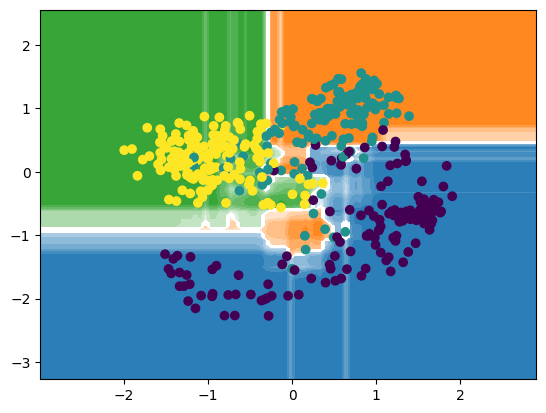

In [13]:
# thinking we do dimensionality reduction to make it 2d...
from sklearn.decomposition import PCA

pca = PCA(n_components=2).fit(X_train)
X_train_2d, X_test_2d = pca.transform(X_train), pca.transform(X_test)

clf = BaggingClassifier(n_estimators=100).fit(X_train_2d, y_train)
print(clf.score(X_test_2d, y_test))

disp = DecisionBoundaryDisplay.from_estimator(clf, X_train_2d, response_method="predict_proba" )
disp.ax_.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train)
plt.show()